# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)


done_brit = pd.read_csv("donnees/consommation_brut.csv")

display(done_brit.shape)

display(done_brit.dtypes)

display(done_brit.isna().sum())

display( done_brit.duplicated().sum())

(300, 4)

mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

np.int64(12)

**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [127]:
display(done_brit["quartier"].nunique())

43

**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [128]:
tes = pd.to_numeric(done_brit["kwh"], errors="coerce")
vale = done_brit.loc[tes.isna() & done_brit["kwh"].notna(), "kwh"]

print(vale.head(12).tolist())

['184410 kWh', '206280 kWh', '215140 kWh', '251 900', '274520 kWh', '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh', '299610 kWh', '373 880']


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [129]:
netwaye = done_brit.copy()
netwaye["kwh"] = (
    netwaye["kwh"]
    .str.replace("kWh", "", regex=False)
    .str.replace(r"\s", "", regex=True)      # espaces, y compris insécables
)
netwaye["kwh"] = pd.to_numeric(netwaye["kwh"], errors="coerce")

print(netwaye["kwh"].isna().sum())

9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [130]:
katye = pd.read_csv("donnees/quartiers.csv")

non = {nom.lower(): nom for nom in katye["quartier"]}
netwaye["quartier"] = netwaye["quartier"].str.strip().str.lower().map(non)

print(netwaye["quartier"].nunique())

12


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [131]:
netwaye = netwaye.drop_duplicates()
netwaye = netwaye.dropna(subset=["kwh"]).reset_index(drop=True)
print(netwaye.shape)

(279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [132]:
medyan = netwaye.groupby("quartier")["kwh"].transform("median")
two_gran = netwaye["kwh"] > 3 * medyan

print(netwaye.loc[two_gran, ["mois", "quartier", "kwh"]])

netwaye.loc[two_gran, "kwh"] = netwaye.loc[two_gran, "kwh"] / 10
netwaye["kwh"] = netwaye["kwh"].round().astype("int64")

print("maximum ", netwaye["kwh"].max())

        mois        quartier        kwh
82   2025-02       Delmas 33  3602600.0
127  2025-02       Delmas 75  2012700.0
187  2024-02  Morne Calvaire  1439200.0
232  2024-01          Rue 15   997700.0
maximum  742780


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [133]:
kle = ["mois", "quartier"]
referans = pd.read_csv("donnees/consommation.csv")

ref = referans.merge(netwaye[kle], on=kle)[list(netwaye.columns)]

a = netwaye.sort_values(kle).reset_index(drop=True)
b = ref.sort_values(kle).reset_index(drop=True)

display(a.equals(b))

True

## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [134]:
avan = len(netwaye)
katye_yo = netwaye.merge(katye, on="quartier", how="left")
print(avan, "->", len(katye_yo))

katye_yo["kwh_par_abonne"] = (katye_yo["kwh"] / katye_yo["abonnes"]).round(1)
katye_yo["annee"] = katye_yo["mois"].str[:4].astype(int)

katye_yo.loc[
    (katye_yo["quartier"] == "Bas-Peu-de-Chose") & (katye_yo["mois"] == "2024-01"),
    ["mois", "quartier", "kwh_par_abonne"],
]

279 -> 279


,mois,quartier,kwh_par_abonne
0,2024-01,Bas-Peu-de-Chose,85.8


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [135]:
meteo = pd.read_csv("donnees/meteo.csv")

avan = len(katye_yo)
akmeteo = katye_yo.merge(meteo, on=["mois", "commune"], how="left")

print("lignes :", avan, "->", len(akmeteo))
print("températures manquantes :", akmeteo["temperature_c"].isna().sum())

lignes : 279 -> 279
températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [136]:
akmeteo.to_csv("donnees/consommation_propre.csv", index=False)

df = pd.read_csv("donnees/consommation_propre.csv")
display(df.shape)

(279, 11)

## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

              quartier         type  kwh_par_abonne
0         Centre-ville   Commercial           468.7
1   Place Saint-Pierre   Commercial           458.3
2            Delmas 33   Commercial           374.4
3               Rue 15   Commercial           268.5
4       Morne Calvaire  Résidentiel           166.1
5            Thomassin  Résidentiel           146.0
6            Delmas 65  Résidentiel           134.9
7           Bois-Verna  Résidentiel           130.1
8            Delmas 75  Résidentiel           118.6
9     Bas-Peu-de-Chose  Résidentiel           100.2
10            Carénage  Résidentiel            72.2
11         Petite-Anse  Résidentiel            69.6


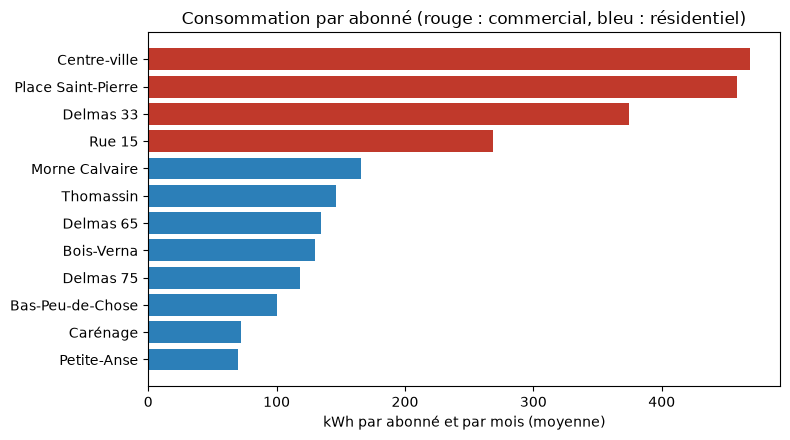

In [140]:
pa_tip = df.groupby("type")["kwh_par_abonne"].mean().round(1)
print(pa_tip)
print()

klasman = (
    df.groupby(["quartier", "type"])["kwh_par_abonne"].mean().round(1)
    .sort_values(ascending=False)
    .reset_index()
)
print(klasman)

fig, ax = plt.subplots(figsize=(8, 4.5))
koule = klasman["type"].map({"Commercial": "#c0392b", "Résidentiel": "#2c7fb8"})
ax.barh(klasman["quartier"][::-1], klasman["kwh_par_abonne"][::-1], color=koule[::-1])
ax.set_xlabel("kWh par abonné et par mois (moyenne)")
ax.set_title("Consommation par abonné (rouge : commercial, bleu : résidentiel)")
plt.tight_layout()

On peut conclure qu'un abonne cmmercial d'un quartier consomme 393KWH en moyenne par mois, plus de 3 fois d'un abonne residentiel qui, en moyenne, consomme 117 KWH

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

In [142]:
tab = df.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
tab["hausse_pct"] = (tab[2025] / tab[2024] - 1) * 100      # calculée avant d'arrondir
tab = tab.sort_values("hausse_pct", ascending=False)

rezime = pd.DataFrame({
    "2024 (M kWh)": (tab[2024] / 1e6).round(2),
    "2025 (M kWh)": (tab[2025] / 1e6).round(2),
    "hausse (%)": tab["hausse_pct"].round(1),
})
rezime

,2024 (M kWh),2025 (M kWh),hausse (%)
commune,,,
Cap-Haïtien,4.59,5.62,22.5
Pétion-Ville,8.60,9.68,12.6
Port-au-Prince,10.09,10.31,2.3
Delmas,11.61,11.74,1.1


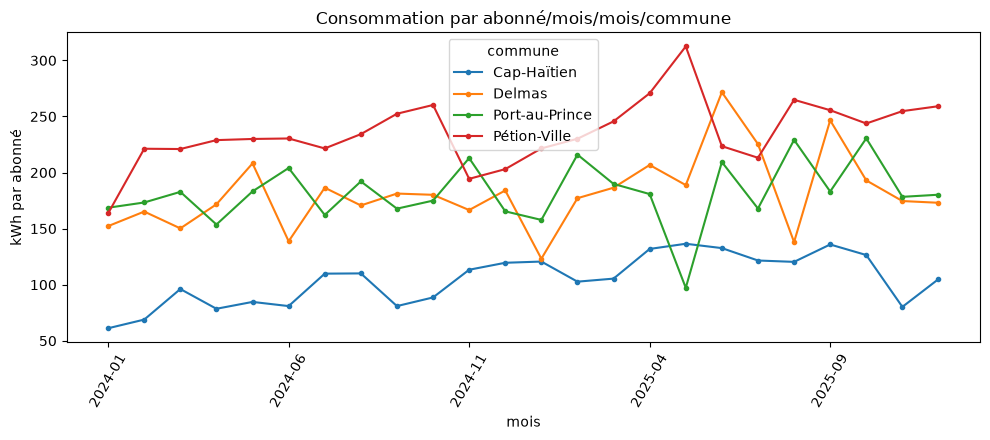

In [145]:
koub = df.groupby(["mois", "commune"]).agg(kwh=("kwh", "sum"), abonnes=("abonnes", "sum"))
koub["par_abonne"] = koub["kwh"] / koub["abonnes"]
koub = koub["par_abonne"].unstack("commune")

ax = koub.plot(figsize=(10, 4.5), marker="o", markersize=3)
ax.set_ylabel("kWh par abonné")
ax.set_xlabel("mois")
ax.set_title("Consommation par abonné/mois/mois/commune")
plt.xticks(rotation=60)
plt.tight_layout()

Cap-Haitien progresse le plus, puis Petion-Ville, Port-au-Prince et Delmas. Sur la courbe, Cap-Haitien monte de facon assez régulière. Les 3 autres communes oscillent beaucoup.

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

0.76 avec les heures de courant
-0.15 avec la temperature


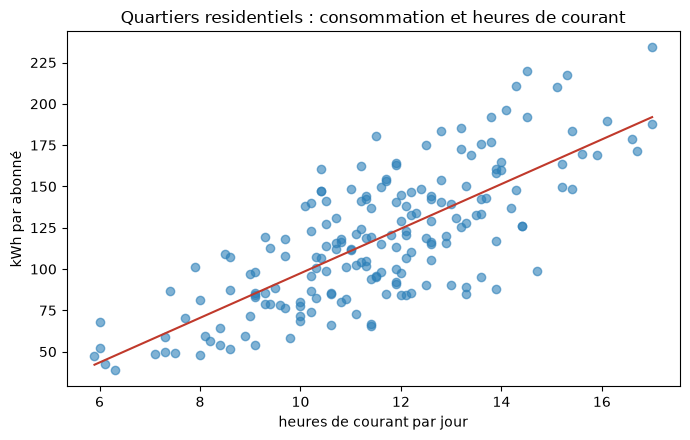

In [148]:
res = df[df["type"] == "Résidentiel"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(res["heures_courant"], res["kwh_par_abonne"], alpha=0.6, color="#2c7fb8")
pant, orijin = np.polyfit(res["heures_courant"], res["kwh_par_abonne"], 1)
xs = np.linspace(res["heures_courant"].min(), res["heures_courant"].max(), 50)
ax.plot(xs, pant * xs + origine, color="#c0392b")
ax.set_xlabel("heures de courant par jour")
ax.set_ylabel("kWh par abonné")
ax.set_title("Quartiers residentiels : consommation et heures de courant")
plt.tight_layout()

print(round(res["kwh_par_abonne"].corr(res["heures_courant"]), 2), "avec les heures de courant")
print(round(res["kwh_par_abonne"].corr(res["temperature_c"]), 2), "avec la temperature")

**Ce qu'on en conclut :** chez les residentiels, la correlation avec les heures de courant est de 0,76, contre -0,15 avec la temperature. Le lien avec les heures de courant se retrouve dans chacun des 8 quartiers, donc il ne vient pas seulement de differences entre quartiers. La temperature ne passe pas non plus par les coupures : elle n'a aucun lien avec les heures de courant.

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

                  Q1  médiane    Q3
commune                            
Cap-Haïtien      8.3     10.0  11.7
Delmas          10.1     11.9  13.0
Port-au-Prince  10.7     11.6  13.1
Pétion-Ville    10.4     11.6  13.0


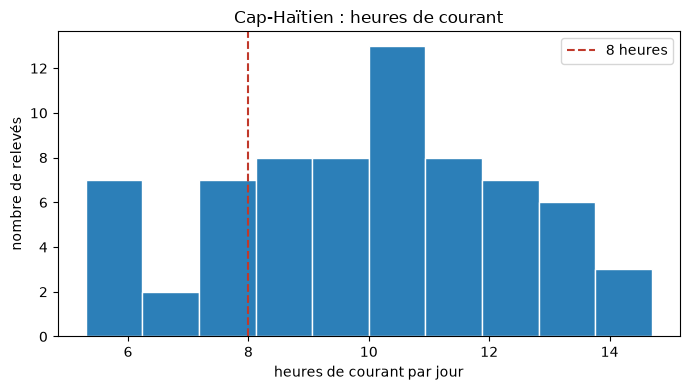

In [150]:
stats = df.groupby("commune")["heures_courant"].quantile([0.25, 0.5, 0.75]).unstack()
stats.columns = ["Q1", "médiane", "Q3"]
print(stats.round(1))

cap = df[df["commune"] == "Cap-Haïtien"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(cap["heures_courant"], bins=10, color="#2c7fb8", edgecolor="white")
ax.axvline(8, color="#c0392b", linestyle="--", label="8 heures")
ax.set_xlabel("heures de courant par jour")
ax.set_ylabel("nombre de relevés")
ax.set_title("Cap-Haïtien : heures de courant")
ax.legend()
plt.tight_layout()

In [154]:
feb = df[(df["annee"] == 2025) & (df["heures_courant"] < 8)]
display(len(feb))
feb[["mois", "quartier", "commune", "heures_courant"]]

3

,mois,quartier,commune,heures_courant
81,2025-01,Delmas 33,Delmas,7.4
227,2025-08,Carénage,Cap-Haïtien,7.3
253,2025-11,Rue 15,Cap-Haïtien,5.9


**Ce qu'on en conclut :** Cap-Haïtien a la médiane la plus basse que les 3 autres communes.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [155]:
df.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]


,mois,quartier,type,kwh
87,2025-07,Delmas 33,Commercial,742780
56,2024-11,Centre-ville,Commercial,597730
88,2025-09,Delmas 33,Commercial,591420


**Ce qu'on en conclut :** les 3 plus grosses consommations sont commerciales.

## 9. Conclusion
La consommation suit les heures de courant, pas la chaleur : chez les résidentiels, la corrélation avec les heures de courant est de 0,76 contre -0,15 avec la température. Ce lien est en partie mécanique, sans courant, pas de consommation et une corrélation ne dit pas ce qui cause quoi : un facteur commun, comme la qualité du réseau ou l'activité du quartier, pourrait jouer sur les deux.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.